# 22542695 PREDICTION OF FOOTBALL MATCH RESULTS USING MACHINE LEARNING MODELS(DATA EXPLORATION)-PART1

## 1. UPLOAD ESSENTIAL LIBRARIES AND THE EPL DATA

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler
from scipy.stats import poisson
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import balanced_accuracy_score
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
import os
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import seaborn as sns
sns.set(
    style='ticks', 
    context='talk', 
    font_scale=0.8, 
    rc={'figure.figsize': (8,6)}
)
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PolynomialFeatures
from sklearn.feature_selection import SelectFromModel
from sklearn.feature_selection import SelectKBest, f_regression, f_classif
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet

from functools import partial


rmse = partial(mean_squared_error, squared=False)
from sklearn.model_selection import cross_val_score
from sklearn.decomposition import PCA
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score

!pip install shap
!pip install -q shap
import shap
shap.initjs()

import random
seed = 42
random.seed(seed)
np.random.seed(seed)

!pip install pandas seaborn matplotlib



C:\Users\chint\anaconda3\lib\site-packages\numpy\_distributor_init.py:30: UserWarning: loaded more than 1 DLL from .libs:
C:\Users\chint\anaconda3\lib\site-packages\numpy\.libs\libopenblas.el2c6ple4zyw3eceviv3oxxgrn2nrfm2.gfortran-win_amd64.dll
C:\Users\chint\anaconda3\lib\site-packages\numpy\.libs\libopenblas.GK7GX5KEQ4F6UYO3P26ULGBQYHGQO7J4.gfortran-win_amd64.dll
  warnings.warn("loaded more than 1 DLL from .libs:"


  Using cached numpy-1.21.6-cp39-cp39-win_amd64.whl (14.0 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.22.4
    Uninstalling numpy-1.22.4:
      Successfully uninstalled numpy-1.22.4


ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'C:\\Users\\chint\\AppData\\Local\\Temp\\pip-uninstall-hr9ry__4\\libopenblas.el2c6ple4zyw3eceviv3oxxgrn2nrfm2.gfortran-win_amd64.dll'
Consider using the `--user` option or check the permissions.



In [2]:
!pip install --upgrade scikit-learn -q --user

In [3]:
folder_path = 'F:/MSc Data Science MMU/Semister 3/Project/THESIS/Football data/fbpdata'
# Grouped the appropriate csv files
csv_files = ['0506E0.csv', '0506E1.csv', '0506E2.csv', '0506E3.csv', '0506EC.csv',
            '0607E0.csv', '0607E1.csv', '0607E2.csv', '0607E3.csv', '0607EC.csv',
            '0708E0.csv', '0708E1.csv', '0708E2.csv', '0708E3.csv', '0708EC.csv',
            '0809E0.csv', '0809E1.csv', '0809E2.csv', '0809E3.csv', '0809EC.csv',
            '0910E0.csv', '0910E1.csv', '0910E2.csv', '0910E3.csv', '0910EC.csv',
            '1011E0.csv', '1011E1.csv', '1011E2.csv', '1011E3.csv', '1011EC.csv',
            '1112E0.csv', '1112E1.csv', '1112E2.csv', '1112E3.csv', '1112EC.csv',
            '1213E0.csv', '1213E1.csv', '1213E2.csv', '1213E3.csv', '1213EC.csv',
            '1314E0.csv', '1314E1.csv', '1314E2.csv', '1314E3.csv', '1314EC.csv',
            '1415E0.csv', '1415E1.csv', '1415E2.csv', '1415E3.csv', '1415EC.csv',
            '1516E0.csv', '1516E1.csv', '1516E2.csv', '1516E3.csv', '1516EC.csv',
            '1617E0.csv', '1617E1.csv', '1617E2.csv', '1617E3.csv', '1617EC.csv',
            '1718E0.csv', '1718E1.csv', '1718E2.csv', '1718E3.csv', '1718EC.csv',
            '1819E0.csv', '1819E1.csv', '1819E2.csv', '1819E3.csv', '1819EC.csv',
            '1920E0.csv', '1920E1.csv', '1920E2.csv', '1920E3.csv', '1920EC.csv',
            '2021E0.csv', '2021E1.csv', '2021E2.csv', '2021E3.csv', '2021EC.csv',
            '2122E0.csv', '2122E1.csv', '2122E2.csv', '2122E3.csv', '2122EC.csv',
            '2223E0.csv', '2223E1.csv', '2223E2.csv', '2223E3.csv', '2223EC.csv']


In [4]:
file_paths = [folder_path + '/' + file for file in csv_files]

In [5]:
# Load and concatenate the CSV files into a single DataFrame
fbdata = pd.concat([pd.read_csv(file, encoding='cp1252') for file in file_paths])


## 2. DATA EXPLORATION

In [6]:
fbdata.head(5)

,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,AvgC<2.5,AHCh,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA
0,E0,13/08/05,Aston Villa,Bolton,2.0,2.0,D,2.0,2.0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,E0,13/08/05,Everton,Man United,0.0,2.0,A,0.0,1.0,A,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,E0,13/08/05,Fulham,Birmingham,0.0,0.0,D,0.0,0.0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,E0,13/08/05,Man City,West Brom,0.0,0.0,D,0.0,0.0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,E0,13/08/05,Middlesbrough,Liverpool,0.0,0.0,D,0.0,0.0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
num_rows = fbdata.shape[0]
print("Numbber of rows:", num_rows)

Numbber of rows: 45969


In [8]:
div_types = fbdata['Div'].unique()
print("Unique types in 'Div' column:", div_types)

Unique types in 'Div' column: ['E0' 'E1' 'E2' 'E3' 'EC' nan]


In [9]:
missing_values = fbdata['Div'].isna().sum()

In [10]:
fbdata.dropna(subset=['Div'], inplace=True)

In [11]:
fbdata.set_index('Div', inplace=True)
fbdata.head(20)

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,Referee,...,AvgC<2.5,AHCh,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA
Div,,,,,,,,,,,,,,,,,,,,,
E0,13/08/05,Aston Villa,Bolton,2.0,2.0,D,2.0,2.0,D,M Riley,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
E0,13/08/05,Everton,Man United,0.0,2.0,A,0.0,1.0,A,G Poll,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
E0,13/08/05,Fulham,Birmingham,0.0,0.0,D,0.0,0.0,D,R Styles,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
E0,13/08/05,Man City,West Brom,0.0,0.0,D,0.0,0.0,D,C Foy,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
E0,13/08/05,Middlesbrough,Liverpool,0.0,0.0,D,0.0,0.0,D,M Halsey,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
E0,13/08/05,Portsmouth,Tottenham,0.0,2.0,A,0.0,1.0,A,B Knight,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
E0,13/08/05,Sunderland,Charlton,1.0,3.0,A,1.0,1.0,D,H Webb,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
E0,13/08/05,West Ham,Blackburn,3.0,1.0,H,0.0,1.0,A,A Wiley,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
E0,14/08/05,Arsenal,Newcastle,2.0,0.0,H,0.0,0.0,D,S Bennett,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
#fbdata= fbdata[fbdata.index !='E0']

In [13]:
fbdata.tail(5)

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,Referee,...,AvgC<2.5,AHCh,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA
Div,,,,,,,,,,,,,,,,,,,,,
EC,29/04/2023,Notts County,York,1.0,1.0,D,1.0,0.0,H,G Rollason,...,3.29,-2.25,1.85,1.95,1.83,1.94,2.28,2.00,1.92,1.86
EC,29/04/2023,Oldham,Bromley,1.0,1.0,D,1.0,0.0,H,R Watkins,...,1.93,0.00,1.70,2.10,1.63,2.23,1.94,2.23,1.75,2.02
EC,29/04/2023,Solihull,Woking,0.0,1.0,A,0.0,0.0,D,A Bannister,...,1.94,0.50,2.02,1.77,2.01,1.79,2.06,1.83,2.00,1.77
EC,29/04/2023,Southend,Wealdstone,2.0,1.0,H,0.0,1.0,A,G Parsons,...,2.02,-1.00,1.75,2.05,1.76,2.05,1.91,2.09,1.78,1.98
EC,29/04/2023,Torquay,Wrexham,1.0,1.0,D,0.0,0.0,D,G Rhodes,...,2.67,1.00,2.08,1.73,1.95,1.83,2.10,1.86,1.99,1.76


In [14]:
fbdata.count()

Date        45952
HomeTeam    45952
AwayTeam    45952
FTHG        45952
FTAG        45952
            ...  
PCAHA        9841
MaxCAHH      9856
MaxCAHA      9856
AvgCAHH      9856
AvgCAHA      9856
Length: 138, dtype: int64

In [15]:
# Identify the data types
fbdata.info()

<class 'pandas.core.frame.DataFrame'>
Index: 45952 entries, E0 to EC
Columns: 138 entries, Date to AvgCAHA
dtypes: float64(130), object(8)
memory usage: 48.7+ MB


It revals 45969 rows of data belongs to E0, E1, E2, E3, EC EPL Football Divisions spreaded through 138 features from Date to AvgCAHA, where 130 features are of floats and 8 objects in the dataset.

In [16]:
fbdata.head(2)

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,Referee,...,AvgC<2.5,AHCh,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA
Div,,,,,,,,,,,,,,,,,,,,,
E0,13/08/05,Aston Villa,Bolton,2.0,2.0,D,2.0,2.0,D,M Riley,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
E0,13/08/05,Everton,Man United,0.0,2.0,A,0.0,1.0,A,G Poll,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
# See the list of features in the data set
all_features = fbdata.columns.tolist()
print(all_features)

['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'Referee', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'GBH', 'GBD', 'GBA', 'IWH', 'IWD', 'IWA', 'LBH', 'LBD', 'LBA', 'SBH', 'SBD', 'SBA', 'WHH', 'WHD', 'WHA', 'SJH', 'SJD', 'SJA', 'VCH', 'VCD', 'VCA', 'Bb1X2', 'BbMxH', 'BbAvH', 'BbMxD', 'BbAvD', 'BbMxA', 'BbAvA', 'BbOU', 'BbMx>2.5', 'BbAv>2.5', 'BbMx<2.5', 'BbAv<2.5', 'BbAH', 'BbAHh', 'BbMxAHH', 'BbAvAHH', 'BbMxAHA', 'BbAvAHA', 'BSH', 'BSD', 'BSA', 'PSH', 'PSD', 'PSA', 'PSCH', 'PSCD', 'PSCA', 'Time', 'MaxH', 'MaxD', 'MaxA', 'AvgH', 'AvgD', 'AvgA', 'B365>2.5', 'B365<2.5', 'P>2.5', 'P<2.5', 'Max>2.5', 'Max<2.5', 'Avg>2.5', 'Avg<2.5', 'AHh', 'B365AHH', 'B365AHA', 'PAHH', 'PAHA', 'MaxAHH', 'MaxAHA', 'AvgAHH', 'AvgAHA', 'B365CH', 'B365CD', 'B365CA', 'BWCH', 'BWCD', 'BWCA', 'IWCH', 'IWCD', 'IWCA', 'WHCH', 'WHCD', 'WHCA', 'VCCH', 'VCCD', 'VCCA', 'MaxCH', 'MaxCD', 'MaxCA', 'AvgCH', 'AvgCD

In [18]:
# fig, chart = plt.subplots()
# data = fbdata['FTR'].value_counts()points =fbdata.index
# frequency = fbdata. valueschart.bar(points,
# frequency)chart.set.title('Frequency of EPL Leage results205-2022')
# chart.set_xlabel('Results Type')
# chart.set_ylabel('Frequency')

### 2.1. Summary Statistics

In [82]:
#Check summary statistics of belived to be influentoial data
summary_stats = fbdata[['FTHG', 'FTAG', 'HTHG', 'HTAG', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'GBH', 'GBD', 'GBA', 'IWH', 'IWD', 'IWA', 'LBH', 'LBD', 'LBA', 'SBH', 'SBD', 'SBA', 'WHH', 'WHD', 'WHA', 'SJH', 'SJD', 'SJA', 'VCH', 'VCD', 'VCA', 'Bb1X2', 'BbMxH', 'BbAvH', 'BbMxD', 'BbAvD', 'BbMxA', 'BbAvA', 'BbOU', 'BbMx>2.5', 'BbAv>2.5', 'BbMx<2.5', 'BbAv<2.5', 'BbAH', 'BbAHh', 'BbMxAHH', 'BbAvAHH', 'BbMxAHA', 'BbAvAHA', 'BSH', 'BSD', 'BSA', 'PSH', 'PSD', 'PSA', 'PSCH', 'PSCD', 'PSCA', 'Time', 'MaxH', 'MaxD', 'MaxA', 'AvgH', 'AvgD', 'AvgA', 'B365>2.5', 'B365<2.5', 'P>2.5', 'P<2.5', 'Max>2.5', 'Max<2.5', 'Avg>2.5', 'Avg<2.5', 'AHh', 'B365AHH', 'B365AHA', 'PAHH', 'PAHA', 'MaxAHH', 'MaxAHA', 'AvgAHH', 'AvgAHA', 'B365CH', 'B365CD', 'B365CA', 'BWCH', 'BWCD', 'BWCA', 'IWCH', 'IWCD', 'IWCA', 'WHCH', 'WHCD', 'WHCA', 'VCCH', 'VCCD', 'VCCA', 'MaxCH', 'MaxCD', 'MaxCA', 'AvgCH', 'AvgCD', 'AvgCA', 'B365C>2.5', 'B365C<2.5', 'PC>2.5', 'PC<2.5', 'MaxC>2.5', 'MaxC<2.5', 'AvgC>2.5', 'AvgC<2.5', 'AHCh', 'B365CAHH', 'B365CAHA', 'PCAHH', 'PCAHA', 'MaxCAHH', 'MaxCAHA', 'AvgCAHH', 'AvgCAHA']].describe()
summary_stats = summary_stats.round(1)
print(summary_stats)

          FTHG     FTAG     HTHG     HTAG       HS       AS      HST      AST  \
count  45952.0  45952.0  45951.0  45951.0  42309.0  42309.0  42309.0  42309.0   
mean       1.4      1.2      0.6      0.5     12.3     10.1      5.3      4.3   
std        1.2      1.1      0.8      0.7      4.8      4.3      2.9      2.5   
min        0.0      0.0      0.0      0.0      0.0      0.0      0.0      0.0   
25%        1.0      0.0      0.0      0.0      9.0      7.0      3.0      2.0   
50%        1.0      1.0      0.0      0.0     12.0     10.0      5.0      4.0   
75%        2.0      2.0      1.0      1.0     15.0     13.0      7.0      6.0   
max        9.0      9.0      7.0      5.0     43.0     35.0     24.0     20.0   

            HF       AF  ...  AvgC<2.5    AHCh  B365CAHH  B365CAHA   PCAHH  \
count  42307.0  42307.0  ...    9856.0  9856.0    9839.0    9839.0  9841.0   
mean      11.1     11.6  ...       1.9    -0.2       1.9       1.9     1.9   
std        3.7      3.8  ...       0

In [83]:
#Check summary statistics of belived to be influentoial data
summary_stats = fbdata[['Date', 'FTR', 'FTHG', 'FTAG', 'HTHG', 'HTAG', 'HS', 'AS', 'HST', 'AST', 'HF', 'AS', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR'  ]].describe()
summary_stats = summary_stats.round(1)
print(summary_stats)

          FTHG     FTAG     HTHG     HTAG       HS       AS      HST      AST  \
count  45952.0  45952.0  45951.0  45951.0  42309.0  42309.0  42309.0  42309.0   
mean       1.4      1.2      0.6      0.5     12.3     10.1      5.3      4.3   
std        1.2      1.1      0.8      0.7      4.8      4.3      2.9      2.5   
min        0.0      0.0      0.0      0.0      0.0      0.0      0.0      0.0   
25%        1.0      0.0      0.0      0.0      9.0      7.0      3.0      2.0   
50%        1.0      1.0      0.0      0.0     12.0     10.0      5.0      4.0   
75%        2.0      2.0      1.0      1.0     15.0     13.0      7.0      6.0   
max        9.0      9.0      7.0      5.0     43.0     35.0     24.0     20.0   

            HF       AS       HF       AF       HC       AC       HY       AY  \
count  42307.0  42309.0  42307.0  42307.0  42309.0  42309.0  45951.0  45951.0   
mean      11.1     10.1     11.1     11.6      5.8      4.8      1.4      1.7   
std        3.7      4.3    

### 2.2. Performance Analysis of teams

In [ ]:
team_performance = fbdata.groupby('HomeTeam').mean()[['FTHG', 'FTAG', 'HTHG', 'HTAG', 'HS', 'AS', 'HST', 'AST', 'HF', 'AS', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR']].reset_index()
#team_operformance_columns= ['Team', 'AvgGoals', 'AvgShots', 'AvgShotsOnTarget']
print(team_performance)

In [73]:
team_performance = fbdata.groupby('HomeTeam').mean()[['FTHG', 'FTAG', 'HTHG', 'HTAG', 'HS', 'AS', 'HST', 'AST', 'HF', 'AS', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR']].reset_index()
#team_operformance_columns= ['Team', 'AvgGoals', 'AvgShots', 'AvgShotsOnTarget']
print(team_performance)

               HomeTeam      FTHG      FTAG      HTHG      HTAG         HS  \
0    AFC Telford United  1.043478  1.130435  0.347826  0.521739   8.565217   
1         AFC Wimbledon  1.329114  1.265823  0.582278  0.556962  11.259494   
2            Accrington  1.534483  1.330049  0.662562  0.544335  12.487685   
3             Aldershot  1.395062  1.232099  0.632099  0.570370   9.071713   
4         Alfreton Town  1.717391  1.739130  0.869565  0.750000  11.054348   
..                  ...       ...       ...       ...       ...        ...   
154              Wolves  1.379581  1.162304  0.638743  0.518325  12.612565   
155             Wrexham  1.586207  0.903941  0.753695  0.413793   9.416667   
156             Wycombe  1.344743  1.095355  0.633252  0.444988  10.850856   
157              Yeovil  1.144963  1.184275  0.538084  0.486486   9.403727   
158                York  1.334459  1.097973  0.611486  0.449324  11.976000   

            AS       HST       AST         HF         AS       

In [22]:
team_performance = fbdata.groupby('AwayTeam').mean()[['FTAG', 'AS', 'AST']].reset_index()
#team_operformance_columns= ['Team', 'AvgGoals', 'AvgShots', 'AvgShotsOnTarget']
print(team_performance)

               AwayTeam      FTAG         AS       AST
0    AFC Telford United  0.913043   8.043478  3.347826
1         AFC Wimbledon  1.073016   9.625397  3.926984
2            Accrington  1.073710  10.496314  4.255528
3             Aldershot  1.176904   9.466135  4.677291
4         Alfreton Town  0.989130   7.869565  3.760870
..                  ...       ...        ...       ...
154              Wolves  1.152231  10.425197  4.301837
155             Wrexham  1.216749   9.472222  4.722222
156             Wycombe  1.208845  10.611794  4.343980
157              Yeovil  1.068796   9.338509  4.288820
158                York  1.209459   8.908000  4.192000

[159 rows x 4 columns]


### 2.3. Home vs Away Performance

In [23]:
home_away_performance = fbdata.groupby('HomeTeam')[['FTHG', 'HS', 'HST']].mean().reset_index()
away_performance = fbdata.groupby('AwayTeam')[['FTAG', 'AS', 'AST']].mean().reset_index()
home_away_performance.columns = ['Team', 'AvgHomeGoals', 'AvgHomeShots', 'AvgHomeShotsOnTarget']
away_performance.columns = ['Team', 'AvgAwayGoals', 'AvgAwayShots', 'AvgAwayShotsOnTarget']
performance_comparison = home_away_performance.merge(away_performance, on='Team')
print(performance_comparison)


                   Team  AvgHomeGoals  AvgHomeShots  AvgHomeShotsOnTarget  \
0    AFC Telford United      1.043478      8.565217              4.913043   
1         AFC Wimbledon      1.329114     11.259494              4.481013   
2            Accrington      1.534483     12.487685              5.371921   
3             Aldershot      1.395062      9.071713              4.290837   
4         Alfreton Town      1.717391     11.054348              5.489130   
..                  ...           ...           ...                   ...   
154              Wolves      1.379581     12.612565              5.277487   
155             Wrexham      1.586207      9.416667              4.178571   
156             Wycombe      1.344743     10.850856              4.400978   
157              Yeovil      1.144963      9.403727              4.133540   
158                York      1.334459     11.976000              5.820000   

     AvgAwayGoals  AvgAwayShots  AvgAwayShotsOnTarget  
0        0.913043  

In [86]:
home_performance = fbdata.groupby('HomeTeam')[['FTHG', 'HS', 'HST']].mean().reset_index()
away_performance = fbdata.groupby('AwayTeam')[['FTAG', 'AS', 'AST']].mean().reset_index()
home_away_performance.columns = ['Team', 'AvgHomeGoals', 'AvgHomeShots', 'AvgHomeShotsOnTarget']
away_performance.columns = ['Team', 'AvgHomeGoals', 'AvgHomeShots', 'AvgHomeShotsOnTarget']
performance_comparision = home_away_performance.merge(away_performance, on='Team')
print(performance_comparision)                                  

                   Team  AvgHomeGoals_x  AvgHomeShots_x  \
0    AFC Telford United        1.043478        8.565217   
1         AFC Wimbledon        1.329114       11.259494   
2            Accrington        1.534483       12.487685   
3             Aldershot        1.395062        9.071713   
4         Alfreton Town        1.717391       11.054348   
..                  ...             ...             ...   
154              Wolves        1.379581       12.612565   
155             Wrexham        1.586207        9.416667   
156             Wycombe        1.344743       10.850856   
157              Yeovil        1.144963        9.403727   
158                York        1.334459       11.976000   

     AvgHomeShotsOnTarget_x  AvgHomeGoals_y  AvgHomeShots_y  \
0                  4.913043        0.913043        8.043478   
1                  4.481013        1.073016        9.625397   
2                  5.371921        1.073710       10.496314   
3                  4.290837        1.17

In [25]:
fbdata.head(2)

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,Referee,...,AvgC<2.5,AHCh,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA
Div,,,,,,,,,,,,,,,,,,,,,
E0,13/08/05,Aston Villa,Bolton,2.0,2.0,D,2.0,2.0,D,M Riley,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
E0,13/08/05,Everton,Man United,0.0,2.0,A,0.0,1.0,A,G Poll,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.4. Win loss Analysis

In [26]:
outcome_frequency = fbdata['FTR'].value_counts()
print(outcome_frequency)

H    19936
A    13892
D    12124
Name: FTR, dtype: int64


### 2.5. Corelation analysis

In [27]:
correlation_matrix = fbdata[['FTHG', 'FTAG', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR']].corr()
print(correlation_matrix)

          FTHG      FTAG        HS        AS       HST       AST        HF  \
FTHG  1.000000 -0.033819  0.255356 -0.063088  0.433339 -0.050687 -0.032989   
FTAG -0.033819  1.000000 -0.056333  0.258942 -0.055908  0.436239 -0.015975   
HS    0.255356 -0.056333  1.000000 -0.107814  0.655372 -0.086628 -0.084172   
AS   -0.063088  0.258942 -0.107814  1.000000 -0.097892  0.660412  0.038851   
HST   0.433339 -0.055908  0.655372 -0.097892  1.000000  0.062756 -0.045680   
AST  -0.050687  0.436239 -0.086628  0.660412  0.062756  1.000000  0.027194   
HF   -0.032989 -0.015975 -0.084172  0.038851 -0.045680  0.027194  1.000000   
AF   -0.041507 -0.013717  0.010856 -0.059030  0.010993 -0.032117  0.170042   
HC    0.000491 -0.013617  0.381839 -0.206187  0.279116 -0.096472 -0.094290   
AC   -0.026352  0.010776 -0.206259  0.366994 -0.108994  0.265034 -0.004214   
HY   -0.061414  0.067959 -0.069493  0.086044 -0.091741  0.042907  0.323633   
AY    0.013048 -0.007903  0.041946 -0.057443  0.010613 -0.047338

### 2.6. Time series analysis

In [28]:
# fbdata['Date'] = pd.to_datetime(fbdata['Date'])
# fbdata.set_index('Date', inplace=True)
# goals_over_time = fbdata.resample('Y').sum()[['FTHG', 'FTAG']]
# print(goals_over_time)

In [29]:
# Reset the index
#fbdata.reset_index(inplace=True)

### 2.7. Referee. Analysis

In [30]:
Referee_statistics = fbdata.groupby('Referee').mean()[['HF', 'AF', 'HY', 'AY', 'FTHG', 'FTAG']]
print(Referee_statistics)

                    HF         AF        HY        AY      FTHG      FTAG
Referee                                                                  
A Ajibola          NaN        NaN  1.363636  1.954545  1.545455  1.090909
A Allison    10.500000  11.500000  1.000000  2.000000  0.500000  0.000000
A Backhouse  10.932961  11.145251  1.427136  1.567839  1.482412  1.105528
A Bannister        NaN        NaN  1.400000  1.600000  1.333333  1.266667
A Bates      10.381818  11.650000  0.981818  1.609091  1.386364  0.990909
...                ...        ...       ...       ...       ...       ...
W Barrett    11.875000  13.625000  1.250000  1.250000  1.875000  0.750000
W Cartmel          NaN        NaN  1.000000  1.312500  1.687500  0.937500
W Finnie     10.902913  11.485437  1.392000  1.696000  1.416000  1.208000
k Stroud     12.000000  19.000000  0.000000  2.000000  0.000000  0.000000
l Mason      11.000000  10.000000  4.000000  1.000000  1.000000  1.000000

[480 rows x 6 columns]


### 2.8. Odd Analysis

In [31]:
odds_columns = ['B365H', 'BWH', 'GBH']
odds_comparision = fbdata[['FTHG', 'FTAG'] + odds_columns]
print(odds_comparision)

     FTHG  FTAG  B365H   BWH   GBH
Div                               
E0    2.0   2.0   2.30  2.10  2.25
E0    0.0   2.0   5.00  4.35  4.25
E0    0.0   0.0   2.37  2.30  2.30
E0    0.0   0.0   1.72  1.65  1.73
E0    0.0   0.0   2.87  2.90  2.70
..    ...   ...    ...   ...   ...
EC    1.0   1.0   1.25  1.21   NaN
EC    1.0   1.0   2.70  2.55   NaN
EC    0.0   1.0   3.80  3.50   NaN
EC    2.0   1.0   1.50  1.44   NaN
EC    1.0   1.0   7.50  5.50   NaN

[45952 rows x 5 columns]


In [32]:
fbdata.head(2)

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,Referee,...,AvgC<2.5,AHCh,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA
Div,,,,,,,,,,,,,,,,,,,,,
E0,13/08/05,Aston Villa,Bolton,2.0,2.0,D,2.0,2.0,D,M Riley,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
E0,13/08/05,Everton,Man United,0.0,2.0,A,0.0,1.0,A,G Poll,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.9. Feature importance

In [33]:
fbdata.head(2)

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,Referee,...,AvgC<2.5,AHCh,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA
Div,,,,,,,,,,,,,,,,,,,,,
E0,13/08/05,Aston Villa,Bolton,2.0,2.0,D,2.0,2.0,D,M Riley,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
E0,13/08/05,Everton,Man United,0.0,2.0,A,0.0,1.0,A,G Poll,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [34]:
importance_scores = fbdata[['FTHG','FTAG', 'HS', 'AS', 'HST', 'AST', 'B365H', 'BWH', 'GBH']].corr()['FTHG'].abs().sort_values(ascending=False)
print(importance_scores)

FTHG     1.000000
HST      0.433339
HS       0.255356
B365H    0.197752
BWH      0.196236
GBH      0.187224
AS       0.063088
AST      0.050687
FTAG     0.033819
Name: FTHG, dtype: float64


In [35]:
importance_scores = fbdata[['FTHG','FTAG', 'HS', 'AS', 'HST', 'AST', 'B365H', 'BWH', 'GBH']].corr()['FTAG'].abs().sort_values(ascending=False)
print(importance_scores)

FTAG     1.000000
AST      0.436239
AS       0.258942
B365H    0.213356
BWH      0.210991
GBH      0.186701
HS       0.056333
HST      0.055908
FTHG     0.033819
Name: FTAG, dtype: float64


### 2.10. Visualization

### General

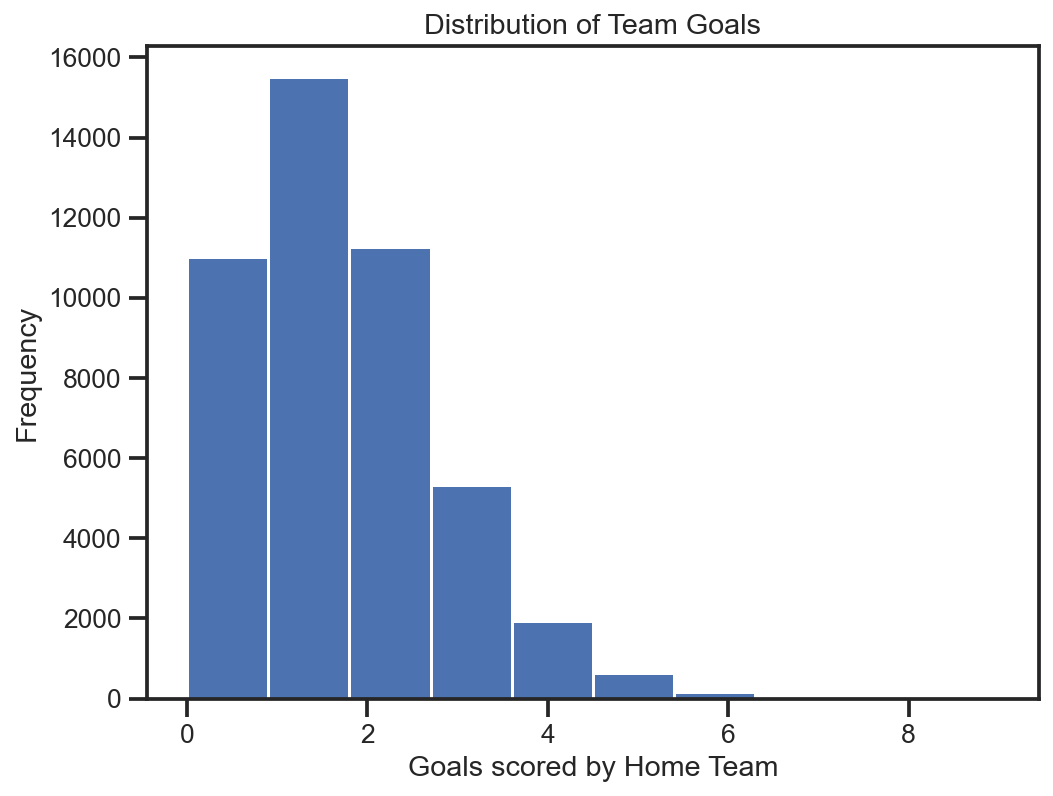

In [36]:
fbdata['FTHG'].plot(kind='hist')
plt.xlabel('Goals scored by Home Team')
plt.ylabel('Frequency')
plt.title('Distribution of Team Goals')
plt.show()

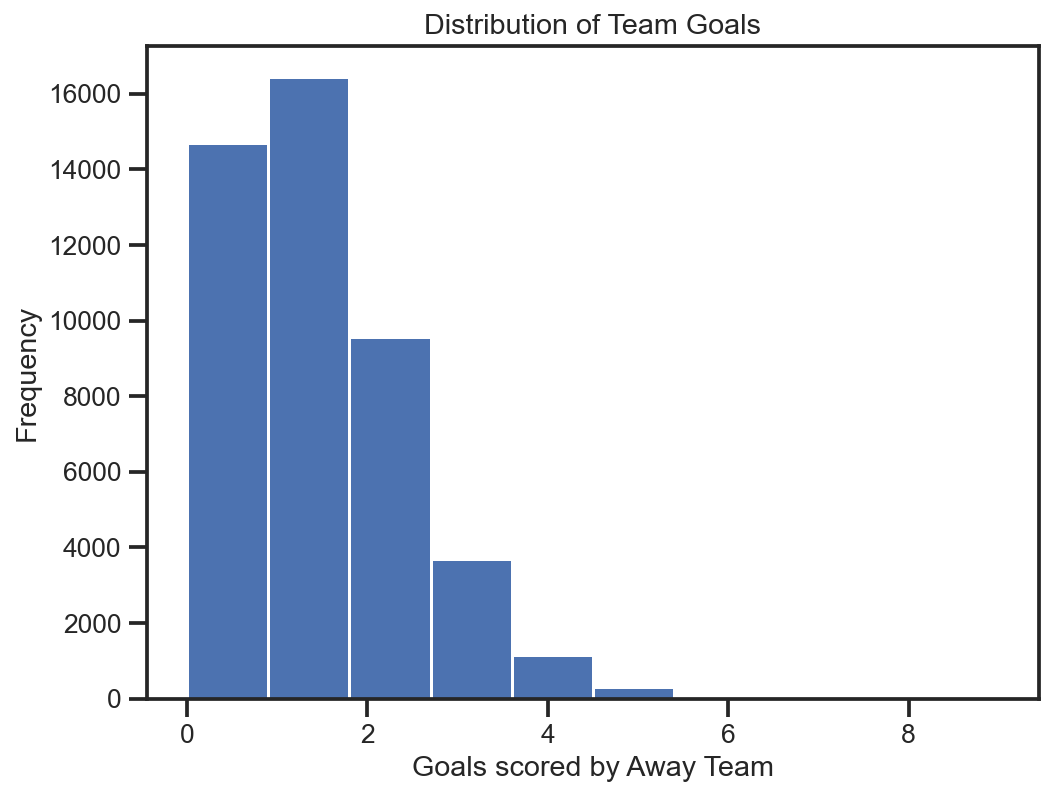

In [37]:
fbdata['FTAG'].plot(kind='hist')
plt.xlabel('Goals scored by Away Team')
plt.ylabel('Frequency')
plt.title('Distribution of Team Goals')
plt.show()

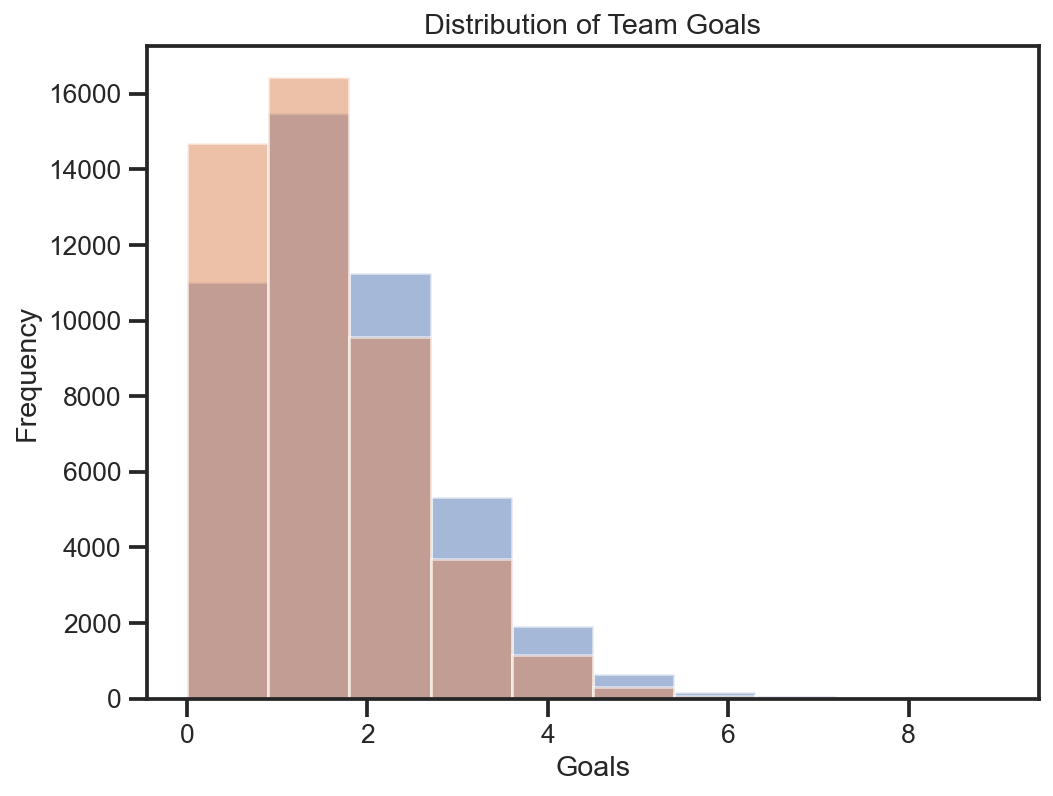

In [38]:
# plot histogrames for comparision of both
plt.hist(fbdata['FTHG'], bins=10, alpha=0.5, label='Home Team Goal')
plt.hist(fbdata['FTAG'], bins=10, alpha=0.5, label='Away Team Goal')
plt.xlabel('Goals')
plt.ylabel('Frequency')
plt.title('Distribution of Team Goals')
plt.show()

### Correlation Matrix

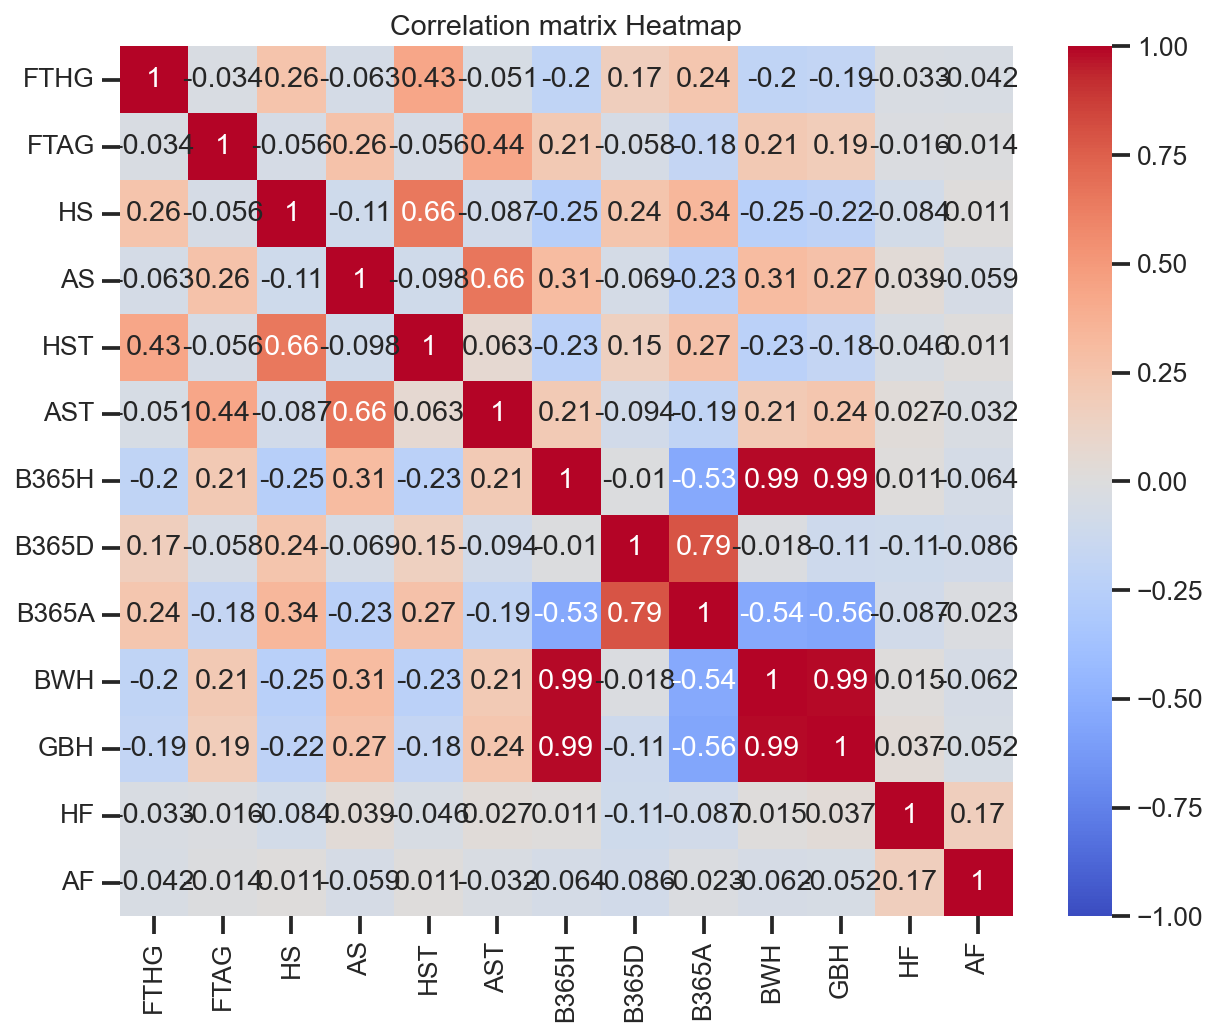

In [39]:
# Calculate the correlation matrix
corr_matrix = fbdata[['FTHG','FTAG', 'HS', 'AS', 'HST', 'AST', 'B365H', 'B365D', 'B365A', 'BWH', 'GBH', 'HF', 'AF']].corr()

# Generate heatmap(anoot=True add the corelation, cmap defines the colour, vmin & vmax spesify the range of values for the colour map)
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin = -1, vmax=1)
plt.title('Correlation matrix Heatmap') 
plt.show()

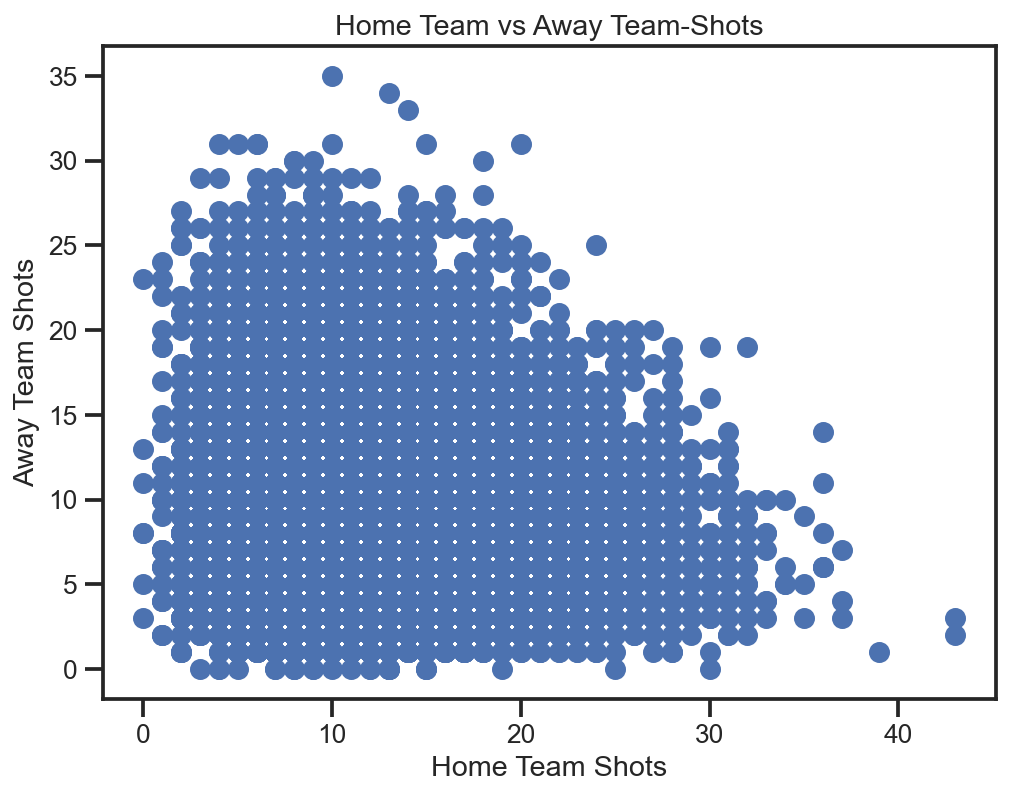

In [40]:
# Lets have a scatter plot
x= fbdata['HS']
y= fbdata['AS']
plt.scatter(x,y)
plt.xlabel('Home Team Shots')
plt.ylabel('Away Team Shots')
plt.title('Home Team vs Away Team-Shots')
plt.show()

In [ ]:
Feature Distribution

In [45]:
# See the list of features in the data set
all_features = fbdata.columns.tolist()
print(all_features)

['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'Referee', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'GBH', 'GBD', 'GBA', 'IWH', 'IWD', 'IWA', 'LBH', 'LBD', 'LBA', 'SBH', 'SBD', 'SBA', 'WHH', 'WHD', 'WHA', 'SJH', 'SJD', 'SJA', 'VCH', 'VCD', 'VCA', 'Bb1X2', 'BbMxH', 'BbAvH', 'BbMxD', 'BbAvD', 'BbMxA', 'BbAvA', 'BbOU', 'BbMx>2.5', 'BbAv>2.5', 'BbMx<2.5', 'BbAv<2.5', 'BbAH', 'BbAHh', 'BbMxAHH', 'BbAvAHH', 'BbMxAHA', 'BbAvAHA', 'BSH', 'BSD', 'BSA', 'PSH', 'PSD', 'PSA', 'PSCH', 'PSCD', 'PSCA', 'Time', 'MaxH', 'MaxD', 'MaxA', 'AvgH', 'AvgD', 'AvgA', 'B365>2.5', 'B365<2.5', 'P>2.5', 'P<2.5', 'Max>2.5', 'Max<2.5', 'Avg>2.5', 'Avg<2.5', 'AHh', 'B365AHH', 'B365AHA', 'PAHH', 'PAHA', 'MaxAHH', 'MaxAHA', 'AvgAHH', 'AvgAHA', 'B365CH', 'B365CD', 'B365CA', 'BWCH', 'BWCD', 'BWCA', 'IWCH', 'IWCD', 'IWCA', 'WHCH', 'WHCD', 'WHCA', 'VCCH', 'VCCD', 'VCCA', 'MaxCH', 'MaxCD', 'MaxCA', 'AvgCH', 'AvgCD

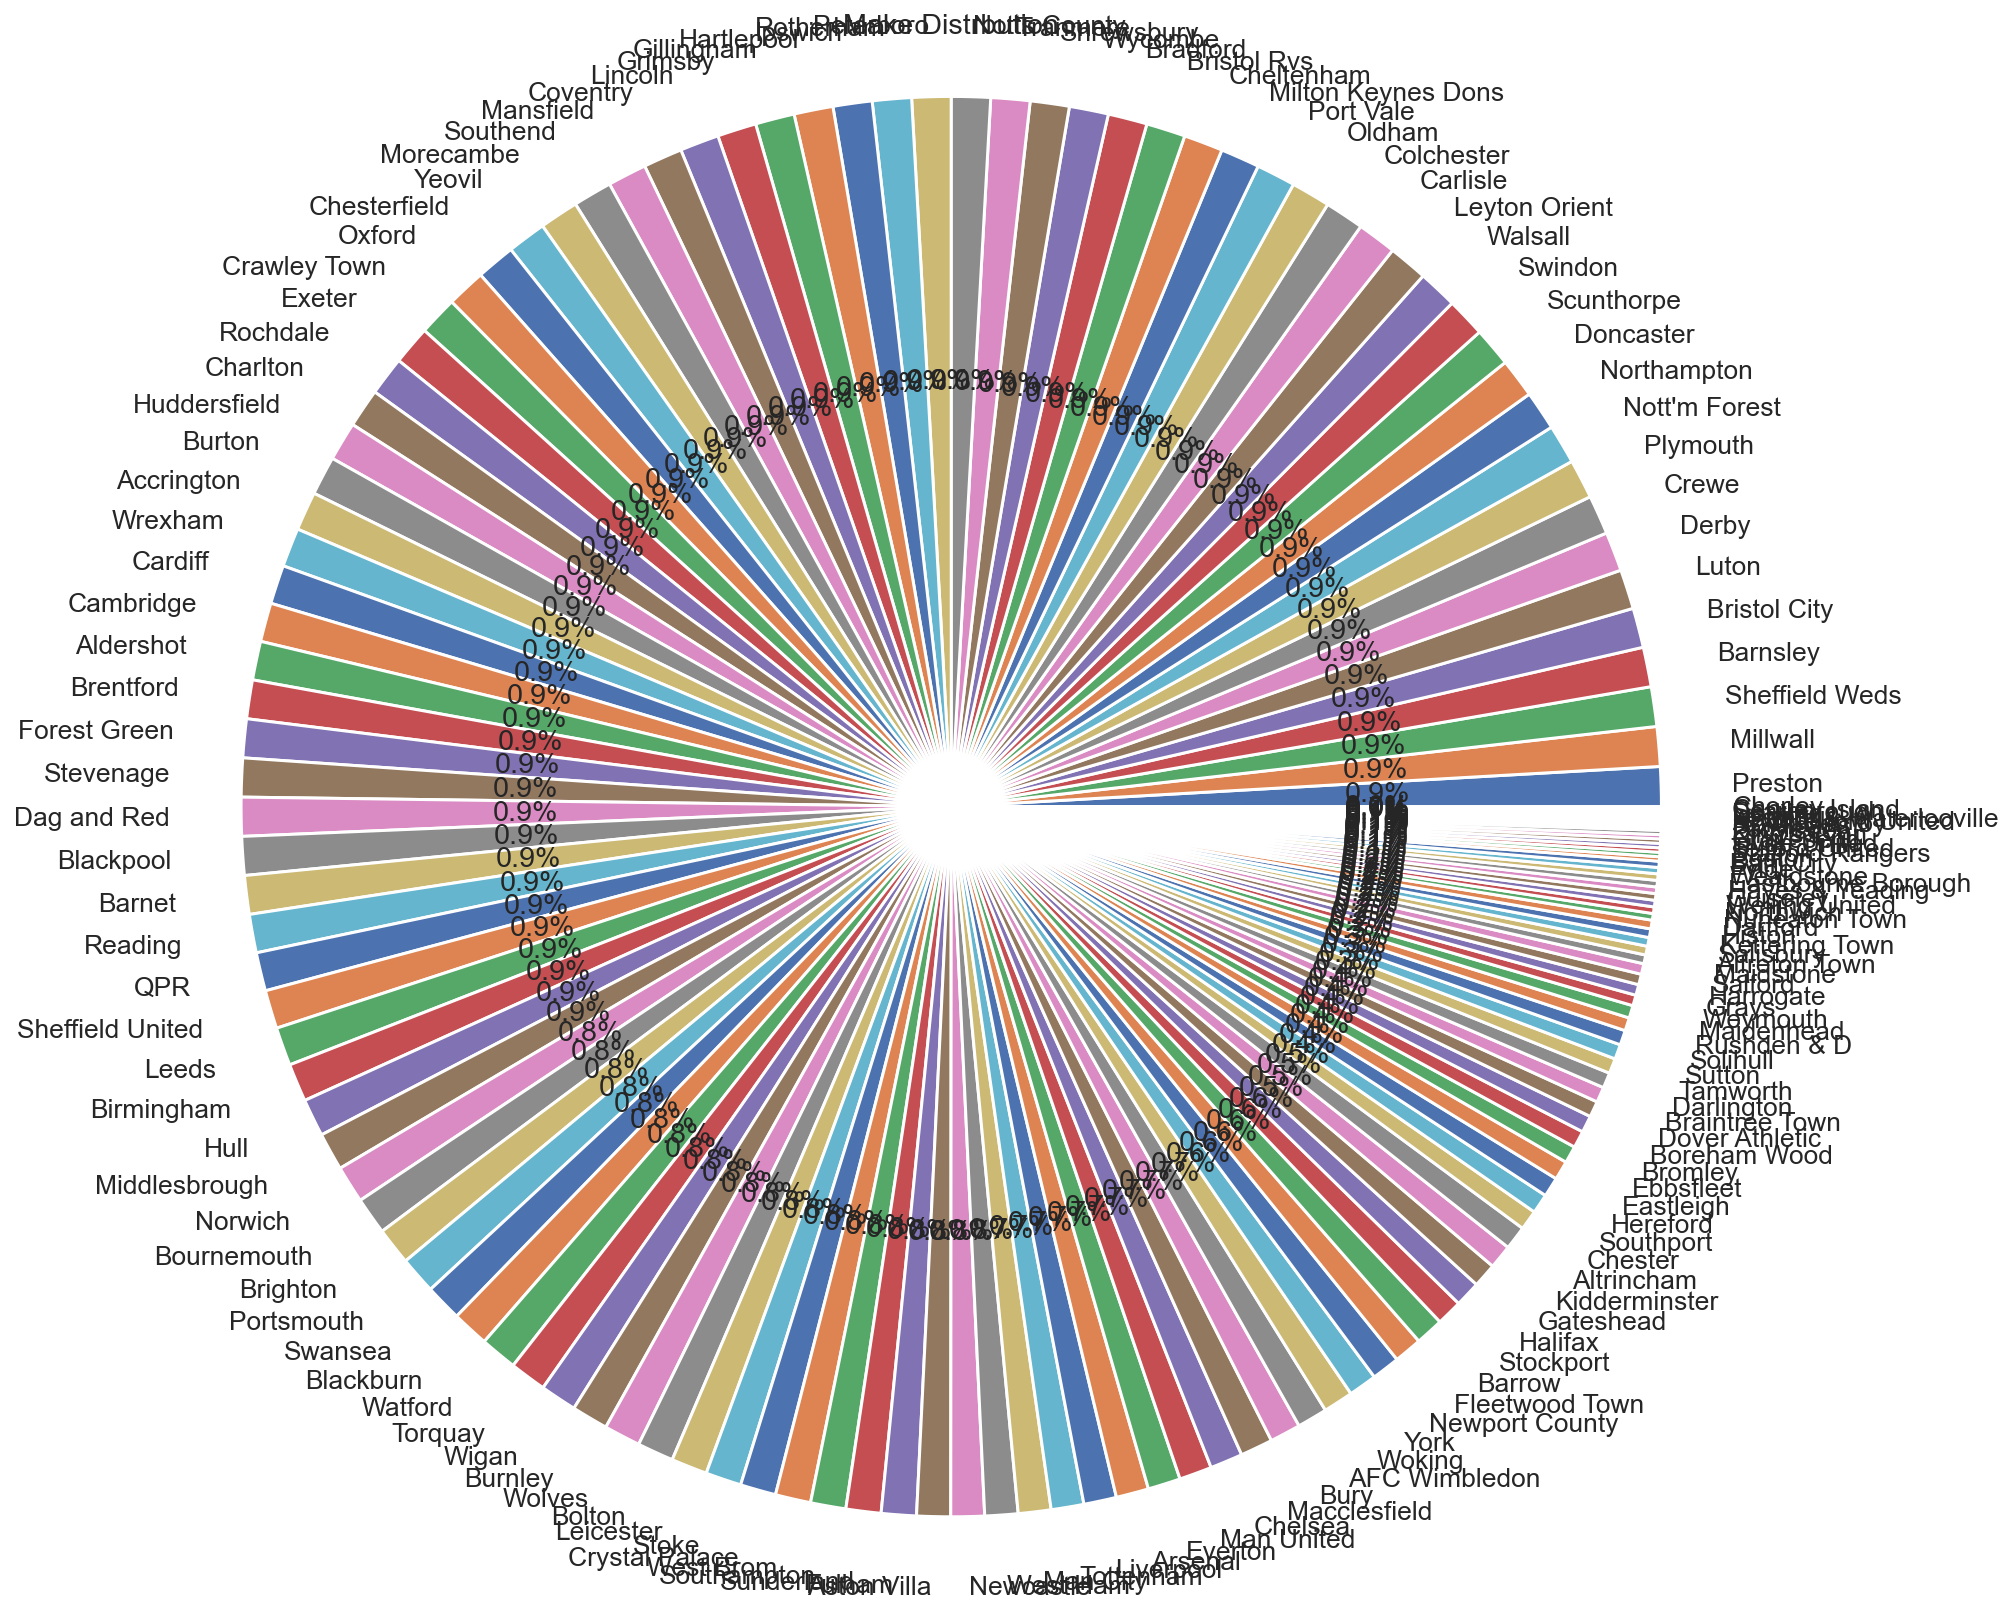

In [62]:
fig, ax =plt.subplots()
ax.pie(fbdata['HomeTeam'].value_counts(normalize=True), labels=fbdata['HomeTeam'].value_counts().index, autopct='%1.1f%%')
ax.axis('equal')
ax.set_title('Make Distrbution')
fig.set_size_inches(14,14)
plt.show()

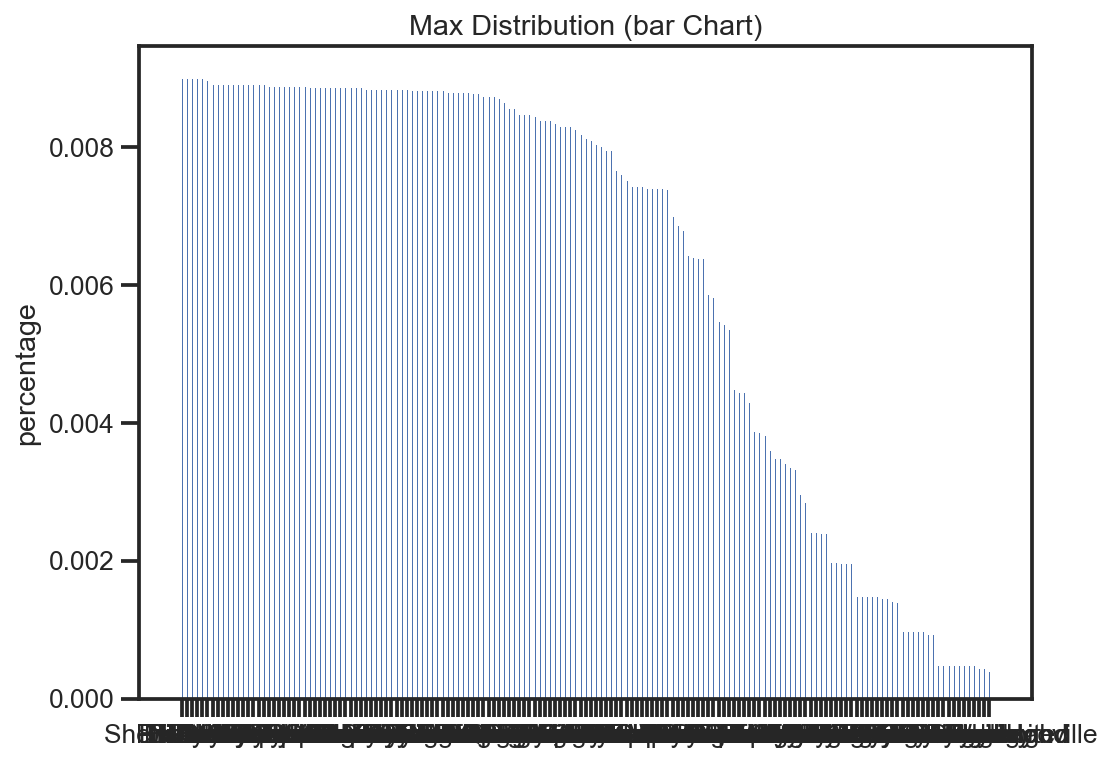

In [71]:
# Convert this to a bar chart
fig2, ax2 = plt.subplots()
ax2.bar(fbdata['HomeTeam'].value_counts().index, fbdata['HomeTeam'].value_counts(normalize=True))
ax2.set_ylabel('percentage')
ax2.set_title('Max Distribution (bar Chart)')
fig.set_size_inches(40,40)
plt.show()

In [47]:
# # Lets visualize numerical features through a histogram
# selected_features =['FTHG', 'FTAG', 'HTHG', 'HTAG', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'GBH', 'GBD', 'GBA', 'IWH', 'IWD', 'IWA', 'LBH', 'LBD', 'LBA', 'SBH', 'SBD', 'SBA', 'WHH', 'WHD', 'WHA', 'SJH', 'SJD', 'SJA', 'VCH', 'VCD', 'VCA', 'BbMxH', 'BbAvH', 'BbMxD', 'BbAvD', 'BbMxA', 'BbAvA', 'BbMx>2.5', 'BbAv>2.5', 'BbMx<2.5', 'BbAv<2.5', 'BbAHh', 'PSH', 'PSD', 'PSA', 'PSCH', 'PSCD', 'PSCA', 'MaxH', 'MaxD', 'MaxA', 'AvgH', 'AvgD', 'AvgA', 'B365>2.5', 'B365<2.5', 'P>2.5', 'P<2.5', 'Max>2.5', 'Max<2.5', 'Avg>2.5', 'Avg<2.5', 'AHh', 'B365AHH', 'B365AHA', 'PAHH', 'PAHA', 'MaxAHH', 'MaxAHA', 'AvgAHH', 'AvgAHA', 'B365CH', 'B365CD', 'B365CA', 'BWCH', 'BWCD', 'BWCA', 'IWCH', 'IWCD', 'IWCA', 'WHCH', 'WHCD', 'WHCA', 'VCCH', 'VCCD', 'VCCA', 'MaxCH', 'MaxCD', 'MaxCA', 'AvgCH', 'AvgCD', 'AvgCA', 'B365C>2.5', 'B365C<2.5', 'PC>2.5', 'PC<2.5', 'MaxC>2.5', 'MaxC<2.5', 'AvgC>2.5', 'AvgC<2.5', 'AHCh', 'B365CAHH', 'B365CAHA', 'PCAHH', 'PCAHA', 'MaxCAHH', 'MaxCAHA', 'AvgCAHH', 'AvgCAHA']

# fig, ax = plt.subplots()
# n, bins, patches = ax.hist(fbdata[selected_features], bins=10, edgecolor='black')
# ax.set_xlabel('Feature')
# ax.set_ylabel('Frequency')
# ax.set_title('Numerical Feature Distribution')

# # label features
# for i , patch in enumerate(patches):
#     for bar in bars:
#         feature_label= selected_features[i]
#         height = bar.get_height()
#         width = patches.get_widht()
#         x = bar.get_x() + width / 2
#         y= height + 5
#         ax.annotate(feature_label, xy=(x,y), xytext=(0, 5), 
#                     textcoords='offset points', ha='center', va='bottom')  

# plt.show()

### Value counts of features

In [49]:
fbdata['FTHG'].value_counts()

1.0    15501
2.0    11262
0.0    11025
3.0     5333
4.0     1924
5.0      651
6.0      173
7.0       63
8.0       16
9.0        4
Name: FTHG, dtype: int64

In [50]:
fbdata['FTAG'].value_counts()

1.0    16436
0.0    14699
2.0     9568
3.0     3697
4.0     1160
5.0      296
6.0       76
7.0       17
9.0        2
8.0        1
Name: FTAG, dtype: int64

In [51]:
fbdata['HST'].value_counts()

4.0     6253
5.0     5976
3.0     5627
6.0     5234
2.0     4059
7.0     4028
8.0     2868
1.0     2105
9.0     1966
10.0    1332
11.0     909
0.0      612
12.0     567
13.0     329
14.0     175
15.0     106
16.0      67
17.0      39
18.0      31
19.0      15
20.0       6
21.0       2
24.0       2
22.0       1
Name: HST, dtype: int64

In [52]:
fbdata['B365H'].value_counts()

2.10    2280
2.50    2099
2.00    2079
2.20    1805
2.25    1661
        ... 
4.25       1
5.80       1
4.90       1
1.38       1
1.05       1
Name: B365H, Length: 142, dtype: int64

In [53]:
fbdata['BWH'].value_counts()

2.10    1972
2.00    1909
2.20    1766
2.25    1663
2.30    1574
        ... 
6.10       1
7.20       1
1.76       1
1.94       1
6.70       1
Name: BWH, Length: 217, dtype: int64

In [54]:
fbdata.isnull()

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,Referee,...,AvgC<2.5,AHCh,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA
Div,,,,,,,,,,,,,,,,,,,,,
E0,False,False,False,False,False,False,False,False,False,False,...,True,True,True,True,True,True,True,True,True,True
E0,False,False,False,False,False,False,False,False,False,False,...,True,True,True,True,True,True,True,True,True,True
E0,False,False,False,False,False,False,False,False,False,False,...,True,True,True,True,True,True,True,True,True,True
E0,False,False,False,False,False,False,False,False,False,False,...,True,True,True,True,True,True,True,True,True,True
E0,False,False,False,False,False,False,False,False,False,False,...,True,True,True,True,True,True,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
EC,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
EC,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
EC,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [55]:
fbdata.isna().sum()

Date            0
HomeTeam        0
AwayTeam        0
FTHG            0
FTAG            0
            ...  
PCAHA       36111
MaxCAHH     36096
MaxCAHA     36096
AvgCAHH     36096
AvgCAHA     36096
Length: 138, dtype: int64

In [56]:
# corr_matrix = fbdata.corr()
# plt.figure(figsize= (10,8))
# sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
# plt.title('Feature Corelation Mettrix')
# plt.show()

In [57]:
# correlation_threshold = 0.5
# potential_components = [component for component in corr_matrix.columns if any(abs(corr_matrix[component]) > correlation_threshold)]
# potential_components.append('Date')
# fbdata = fbdata[potential_components]
# fbdata

In [58]:
fbdata.head(2)

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,Referee,...,AvgC<2.5,AHCh,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA
Div,,,,,,,,,,,,,,,,,,,,,
E0,13/08/05,Aston Villa,Bolton,2.0,2.0,D,2.0,2.0,D,M Riley,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
E0,13/08/05,Everton,Man United,0.0,2.0,A,0.0,1.0,A,G Poll,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
